# Project Assignment PT1 — Data Exploration, Exploratory Data Analysis (EDA), and Baseline Models
**Course:** Machine Learning | **Task:** Human Activity Recognition (HAR)  
**Dataset:** WISDM Activity Prediction v1.1 (`WISDM_ar_v1.1_raw.txt`)

## Objectives
1. Load, clean, and inspect the raw triaxial smartphone accelerometer dataset.
2. Perform Exploratory Data Analysis (EDA) across activities and participants using scientifically accurate shared scales.
3. Provide an interactive signal exploration dashboard (both in-notebook via `Plotly + ipywidgets` and as a standalone `dashboard.py` Streamlit app).
4. Segment continuous sequences into fixed-length sliding windows (**51 samples**, **step size 26**, **~49% overlap**) without crossing participant or activity boundaries.
5. Partition data using a strict **Subject-Wise Split** (Train / Validation / Test) to prevent data leakage.
6. Train and evaluate baseline models (**Majority Class**, **Logistic Regression**, **Decision Tree**) using Accuracy, per-class Precision/Recall/F1, **Macro-F1**, and Confusion Matrices.

---
## Part 1: Raw Data Loading, Cleaning, and Structural Inspection

The raw file `WISDM_ar_v1.1_raw.txt` contains several formatting artifacts:
- Semicolon-delimited records (with occasional multiple records per line and empty trailing segments).
- Spurious trailing commas before semicolons on 11,733 valid records (`user,activity,ts,x,y,z,;`).
- Missing sensor values (e.g., missing `Z` coordinate on line 343,420).
- Zero timestamps (`timestamp == 0`) and all-zero sensor readings (`x = y = z = 0`).

The cell below automatically extracts `WISDM_ar_v1.1_raw.txt` if `WISDM_ar_latest.tar.gz` is uploaded, cleans formatting artifacts safely, and logs every anomaly.

In [1]:
import os
import tarfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# Uncomment below if loading from Google Drive in Colab:
# from google.colab import drive
# drive.mount('/content/drive')
# ARCHIVE_PATH = '/content/drive/MyDrive/WISDM_ar_latest.tar.gz'
# DATA_PATH = '/content/drive/MyDrive/WISDM_ar_v1.1_raw.txt'

ARCHIVE_PATH = "WISDM_ar_latest.tar.gz"
DATA_PATH = "WISDM_ar_v1.1_raw.txt"

# Auto-extract WISDM_ar_v1.1_raw.txt if only the .tar.gz archive is present
if not os.path.exists(DATA_PATH) and os.path.exists(ARCHIVE_PATH):
    with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
        for member in tar.getmembers():
            if member.name.endswith("WISDM_ar_v1.1_raw.txt"):
                f_in = tar.extractfile(member)
                with open(DATA_PATH, "wb") as f_out:
                    f_out.write(f_in.read())
                print(f"Extracted {DATA_PATH} from {ARCHIVE_PATH}")
                break

def load_wisdm_raw(filepath):
    """Safely load and clean WISDM v1.1 raw text data while logging structural anomalies."""
    records = []
    stats = {
        "raw_lines": 0,
        "empty_segments": 0,
        "trailing_comma_recovered": 0,
        "malformed_segments": 0,
        "missing_or_nan_values": 0,
        "zero_timestamps": 0,
    }

    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            stats["raw_lines"] += 1
            segments = line.strip().split(";")
            for seg in segments:
                seg = seg.strip()
                if not seg:
                    stats["empty_segments"] += 1
                    continue
                parts = [p.strip() for p in seg.split(",")]
                # Recover rows with a spurious trailing comma before ';'
                if len(parts) == 7 and parts[6] == "":
                    parts = parts[:6]
                    stats["trailing_comma_recovered"] += 1
                if len(parts) != 6:
                    stats["malformed_segments"] += 1
                    continue
                user_str, activity, ts_str, x_str, y_str, z_str = parts
                if "" in (user_str, activity, ts_str, x_str, y_str, z_str):
                    stats["missing_or_nan_values"] += 1
                    continue
                try:
                    user_id = int(user_str)
                    timestamp = int(ts_str)
                    x, y, z = float(x_str), float(y_str), float(z_str)
                    if np.isnan(x) or np.isnan(y) or np.isnan(z):
                        stats["missing_or_nan_values"] += 1
                        continue
                    if timestamp == 0:
                        stats["zero_timestamps"] += 1
                    records.append((user_id, activity, timestamp, x, y, z))
                except ValueError:
                    stats["malformed_segments"] += 1

    df = pd.DataFrame(records, columns=["user_id", "activity", "timestamp", "x", "y", "z"])
    return df, stats

df, parse_stats = load_wisdm_raw(DATA_PATH)

print("=== Raw File Parsing & Anomaly Report ===")
for k, v in parse_stats.items():
    print(f"{k:28s}: {v:,}")

print(f"\nTotal valid records : {len(df):,}")
print(f"Unique participants : {df['user_id'].nunique()}")
print(f"Unique activities   : {df['activity'].nunique()} -> {sorted(df['activity'].unique())}")
print("\nSample records:")
display(df.head(10))

Extracted WISDM_ar_v1.1_raw.txt from WISDM_ar_latest.tar.gz
=== Raw File Parsing & Anomaly Report ===
raw_lines                   : 1,098,210
empty_segments              : 1,098,209
trailing_comma_recovered    : 11,733
malformed_segments          : 0
missing_or_nan_values       : 1
zero_timestamps             : 12,845

Total valid records : 1,098,208
Unique participants : 36
Unique activities   : 6 -> ['Downstairs', 'Jogging', 'Sitting', 'Standing', 'Upstairs', 'Walking']

Sample records:


,user_id,activity,timestamp,x,y,z
0,33,Jogging,49105962326000,-0.694638,12.680544,0.503953
1,33,Jogging,49106062271000,5.012288,11.264028,0.953424
2,33,Jogging,49106112167000,4.903325,10.882658,-0.081722
3,33,Jogging,49106222305000,-0.612916,18.496431,3.023717
4,33,Jogging,49106332290000,-1.184970,12.108489,7.205164
5,33,Jogging,49106442306000,1.375655,-2.492524,-6.510526
6,33,Jogging,49106542312000,-0.612916,10.569390,5.706926
7,33,Jogging,49106652389000,-0.503953,13.947236,7.055340
8,33,Jogging,49106762313000,-8.430995,11.413852,5.134871
9,33,Jogging,49106872299000,0.953424,1.375655,1.648062


Missing values after cleaning:
 user_id      0
activity     0
timestamp    0
x            0
y            0
z            0
dtype: int64

Exact duplicate rows          : 66,820
Rows with timestamp == 0      : 12,845
Rows with (x, y, z) == (0,0,0): 12,841
X range: [-19.61, 19.95]
Y range: [-19.61, 20.04]
Z range: [-19.80, 19.61]

=== Activity Distribution ===


,Count,Percentage (%)
activity,,
Walking,424399,38.64
Jogging,342179,31.16
Upstairs,122869,11.19
Downstairs,100427,9.14
Sitting,59939,5.46
Standing,48395,4.41



Min records per user : 11,371 (User 4)
Max records per user : 56,632 (User 20)
Mean records per user: 30,505.8
Participants with all 6 activities: 19 / 36


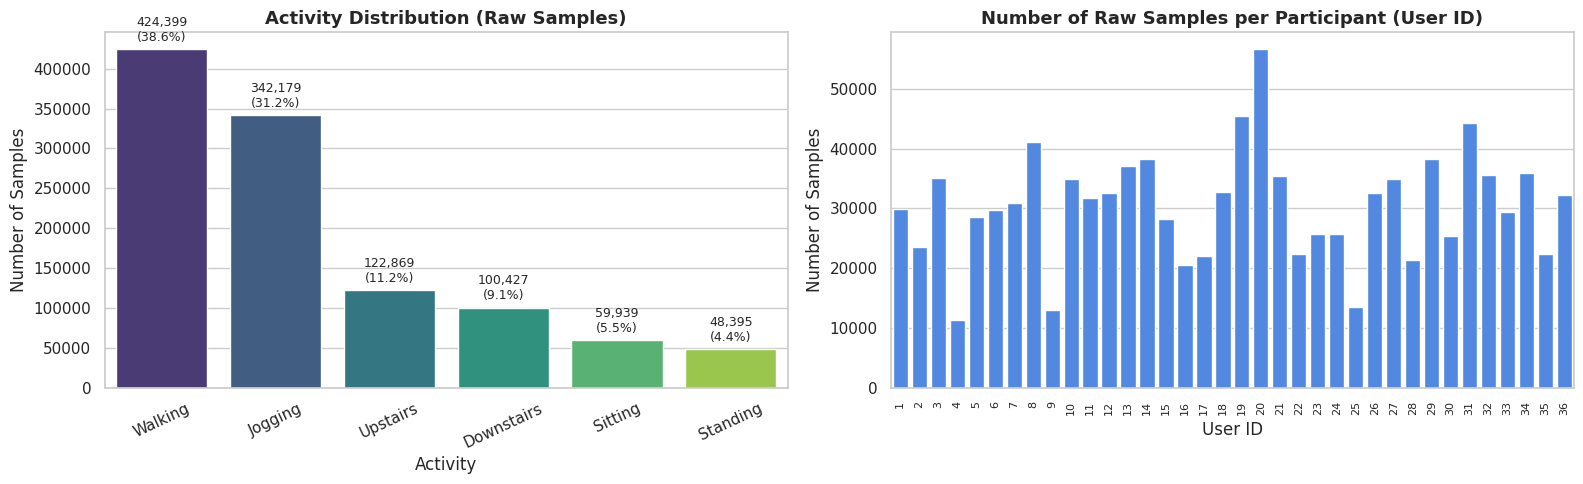

In [2]:
activities_order = ["Walking", "Jogging", "Upstairs", "Downstairs", "Sitting", "Standing"]

# 1. Data quality checks
print("Missing values after cleaning:\n", df.isna().sum())
print(f"\nExact duplicate rows          : {df.duplicated().sum():,}")
print(f"Rows with timestamp == 0      : {(df['timestamp'] == 0).sum():,}")
print(f"Rows with (x, y, z) == (0,0,0): {((df['x'] == 0) & (df['y'] == 0) & (df['z'] == 0)).sum():,}")
print(f"X range: [{df['x'].min():.2f}, {df['x'].max():.2f}]")
print(f"Y range: [{df['y'].min():.2f}, {df['y'].max():.2f}]")
print(f"Z range: [{df['z'].min():.2f}, {df['z'].max():.2f}]")

# 2. Activity counts
act_counts = df["activity"].value_counts().reindex(activities_order)
act_pct = (act_counts / len(df)) * 100
act_summary = pd.DataFrame({"Count": act_counts, "Percentage (%)": act_pct.round(2)})
print("\n=== Activity Distribution ===")
display(act_summary)

# 3. Participant coverage
user_counts = df["user_id"].value_counts().sort_index()
print(f"\nMin records per user : {user_counts.min():,} (User {user_counts.idxmin()})")
print(f"Max records per user : {user_counts.max():,} (User {user_counts.idxmax()})")
print(f"Mean records per user: {user_counts.mean():,.1f}")

user_act_matrix = pd.crosstab(df["user_id"], df["activity"])
complete_users = user_act_matrix[(user_act_matrix > 0).all(axis=1)].index.tolist()
print(f"Participants with all 6 activities: {len(complete_users)} / {df['user_id'].nunique()}")

# 4. Bar charts
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=act_counts.index, y=act_counts.values, palette="viridis", ax=axes[0])
axes[0].set_title("Activity Distribution (Raw Samples)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Activity")
axes[0].set_ylabel("Number of Samples")
axes[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(act_counts.values):
    axes[0].text(
        i, v + max(act_counts.values) * 0.015,
        f"{v:,}\n({act_pct.iloc[i]:.1f}%)",
        ha="center", va="bottom", fontsize=9
    )

sns.barplot(x=user_counts.index, y=user_counts.values, color="#3b82f6", ax=axes[1])
axes[1].set_title("Number of Raw Samples per Participant (User ID)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("User ID")
axes[1].set_ylabel("Number of Samples")
axes[1].tick_params(axis="x", rotation=90, labelsize=8)

plt.tight_layout()
plt.show()

### Analysis — Part 1 Questions
- **Are all activities equally represented?** No; the dataset is heavily imbalanced.
- **Most and least frequent activities:** **Walking** (~38.64%, 424,399 samples) has the most samples, while **Standing** (~4.41%, 48,395 samples) has the fewest (followed closely by **Sitting** at ~5.46%, 59,939 samples).
- **Do all participants have equal amounts of data?** No; record counts range from 11,371 (User 4) to 56,632 (User 20), with an average of ~30,506 records per participant. Only 19 out of 36 participants recorded all 6 activities.
- **Impact of class imbalance on classifiers:** Standard classifiers minimizing overall error become biased toward majority classes (`Walking`, `Jogging`), often yielding poor recall on minority classes (`Standing`, `Sitting`, `Downstairs`) while still displaying deceptively high overall accuracy.

---
## Part 2: Exploratory Data Analysis (EDA) & Interactive Dashboard

### 2-1. Descriptive Statistics per Activity
We compute mean, standard deviation, min, max, and quartiles (25%, 50%, 75%) for each accelerometer axis (`X`, `Y`, `Z`) as well as the orientation-invariant **Signal Vector Magnitude** ($\|\mathbf{a}\| = \sqrt{x^2 + y^2 + z^2}$).

=== Descriptive Statistics (X, Y, Z, Magnitude) by Activity ===


x                                                       y  \
               count   mean    std    min   25%   50%   75%    max     count   
activity                                                                       
Downstairs  100427.0  0.472  4.956 -19.61 -2.18  0.08  2.83  19.95  100427.0   
Jogging     342179.0 -0.202  9.109 -19.61 -5.43  0.00  5.18  19.95  342179.0   
Sitting      59939.0  1.856  4.759 -10.31 -1.61  1.53  5.75  12.45   59939.0   
Standing     48395.0 -1.178  3.235 -10.99 -2.03 -1.12  0.61  13.10   48395.0   
Upstairs    122869.0  0.381  5.495 -19.61 -2.26  0.15  3.06  19.95  122869.0   
Walking     424399.0  1.528  5.793 -19.61 -2.15  0.95  4.82  19.91  424399.0   

                   ...      z              mag                               \
             mean  ...    75%    max     count    mean    std    min    25%   
activity           ...                                                        
Downstairs  8.600  ...  2.750  19.34  100427.0  10.832  4.437  0.000  7.792   
Jogging     5.461  ...  3.296  19.61  342179.0  13.411  7.221  0.000  7.486   
Sitting     1.853  ...  8.920  13.99   59939.0   9.847  0.392  1.345  9.579   
Standing    8.987  ...  1.420   7.25   48395.0   9.815  0.360  0.000  9.643   
Upstairs    8.112  ...  2.070  19.19  122869.0  10.697  4.298  0.000  8.098   
Walking     8.702  ...  1.690  19.23  424399.0  11.429  4.708  0.000  7.996   

                                    
               50%     75%     max  
activity                            
Downstairs  10.175  13.506  31.838  
Jogging     13.163  19.554  33.378  
Sitting      9.957  10.122  19.596  
Standing     9.888  10.006  19.847  
Upstairs    10.186  13.036  32.237  
Walking     11.027  14.400  31.709  

[6 rows x 32 columns]

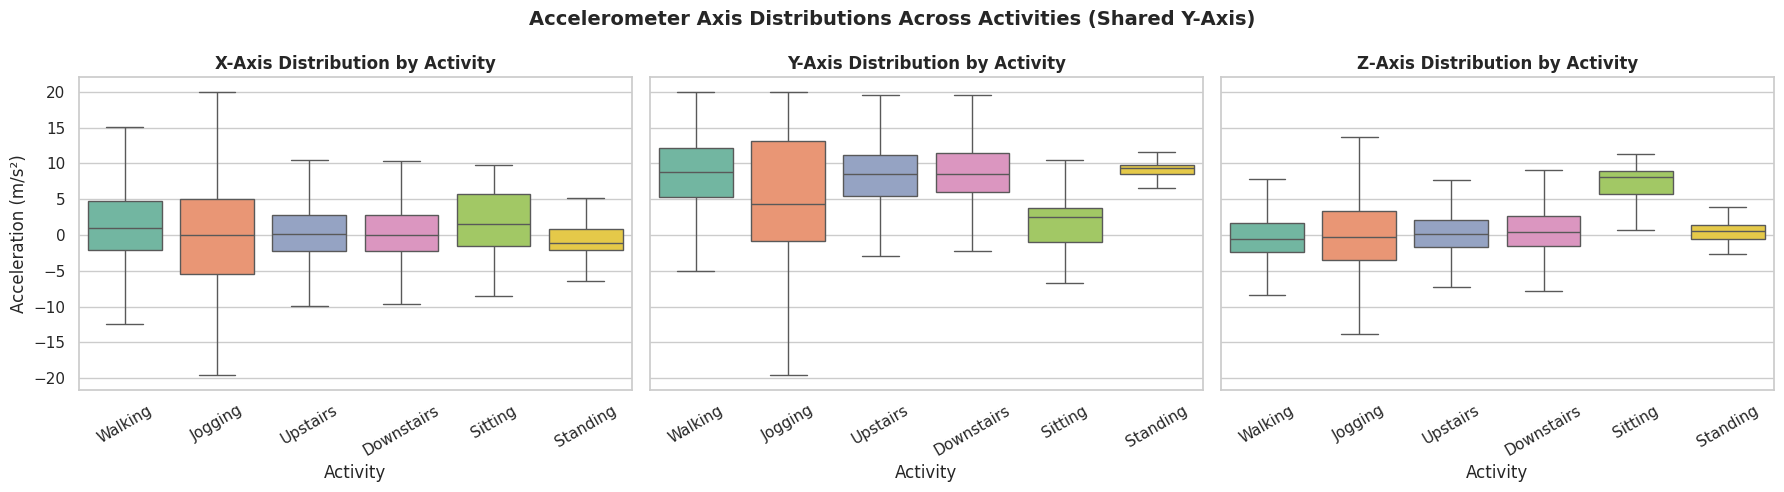

In [3]:
df["mag"] = np.sqrt(df["x"]**2 + df["y"]**2 + df["z"]**2)

desc_stats = df.groupby("activity")[["x", "y", "z", "mag"]].describe(percentiles=[0.25, 0.5, 0.75])
print("=== Descriptive Statistics (X, Y, Z, Magnitude) by Activity ===")
display(desc_stats.round(3))

# Comparative boxplots with shared Y-axis
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
sample_df = df.sample(min(100000, len(df)), random_state=RANDOM_STATE)

for ax, col in zip(axes, ["x", "y", "z"]):
    sns.boxplot(
        data=sample_df, x="activity", y=col,
        order=activities_order, palette="Set2", ax=ax, showfliers=False
    )
    ax.set_title(f"{col.upper()}-Axis Distribution by Activity", fontweight="bold")
    ax.set_xlabel("Activity")
    ax.set_ylabel("Acceleration (m/s²)")
    ax.tick_params(axis="x", rotation=30)

plt.suptitle("Accelerometer Axis Distributions Across Activities (Shared Y-Axis)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 2-2. Visual Comparison of All 6 Activities (Shared Y-Scale)
We select a single participant who recorded all 6 activities and plot 51-sample windows (~2.55 seconds at 20 Hz) using an **identical vertical axis range** across all subplots so amplitude differences are never distorted.

Selected common participant for 6-activity comparison: User 3


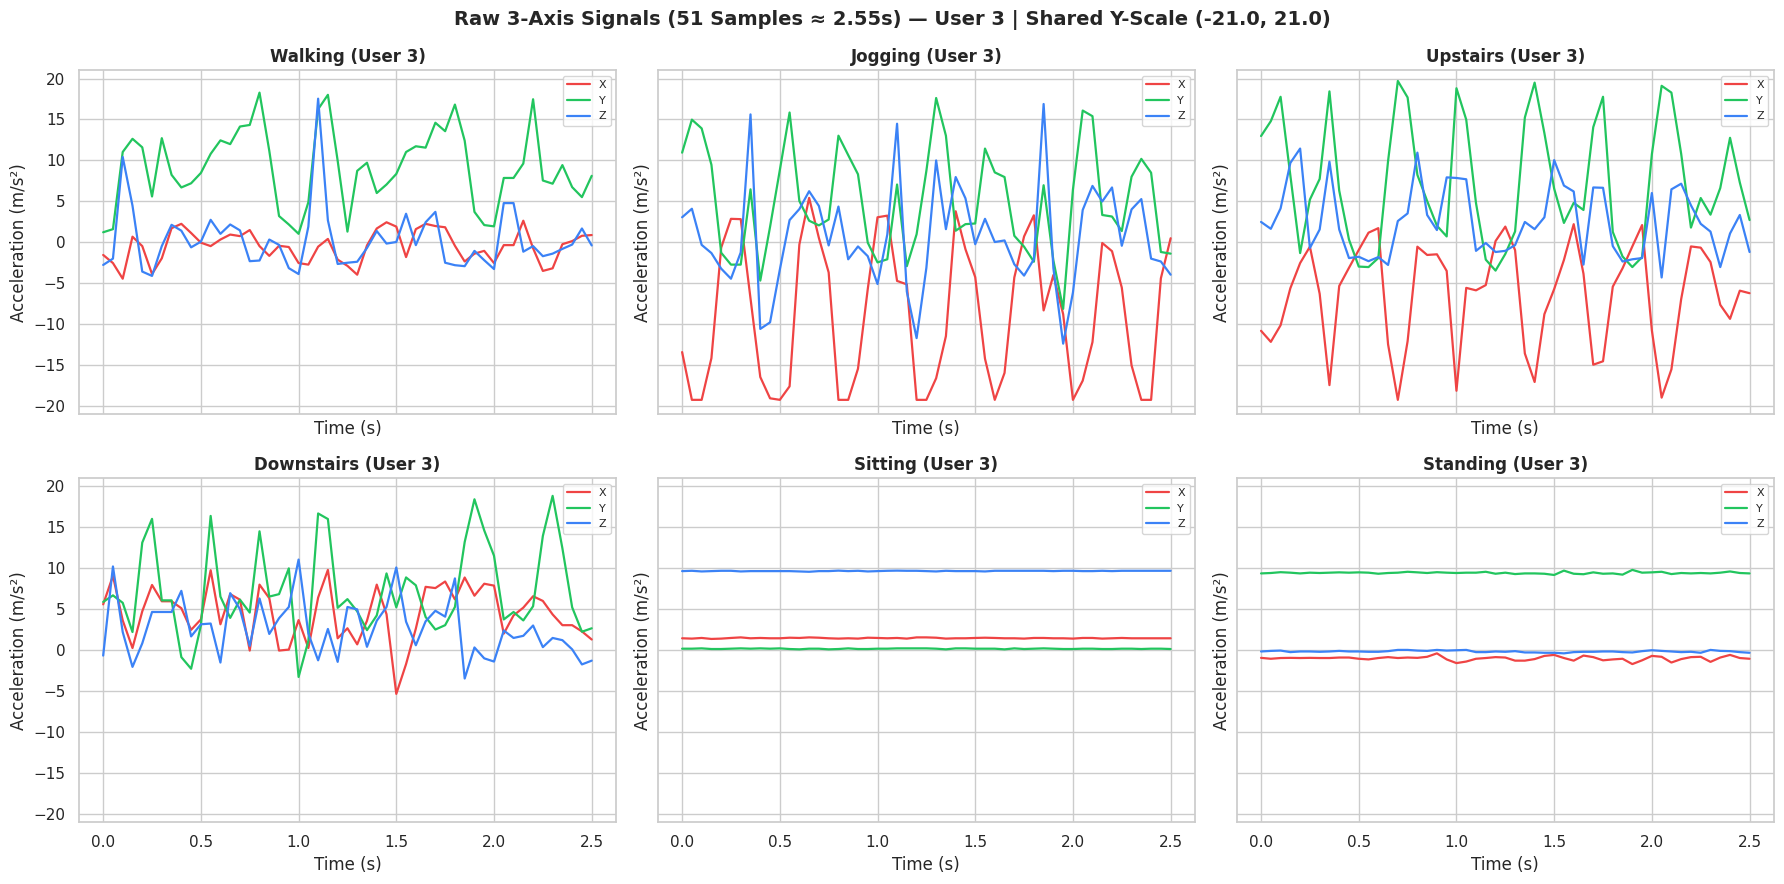

In [4]:
WINDOW_SIZE = 51
FS = 20.0  # Nominal sampling rate (Hz)
TIME_AXIS = np.arange(WINDOW_SIZE) / FS

def get_clean_window(dataframe, user_id, activity, window_size=51, offset=150):
    """Extract a contiguous 51-sample window for a given user and activity."""
    sub = dataframe[(dataframe["user_id"] == user_id) & (dataframe["activity"] == activity)].reset_index(drop=True)
    if len(sub) < window_size:
        return None
    start = min(offset, max(0, len(sub) - window_size))
    return sub.iloc[start : start + window_size]

valid_common_users = user_act_matrix[(user_act_matrix >= 300).all(axis=1)].index.tolist()
common_user = valid_common_users[0] if valid_common_users else complete_users[0]
print(f"Selected common participant for 6-activity comparison: User {common_user}")

windows_6 = {act: get_clean_window(df, common_user, act, WINDOW_SIZE, offset=150) for act in activities_order}

all_vals = np.concatenate([w[["x", "y", "z"]].values.ravel() for w in windows_6.values()])
y_lim = (float(np.floor(all_vals.min()) - 1), float(np.ceil(all_vals.max()) + 1))

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True, sharey=True)
axes = axes.ravel()

for ax, act in zip(axes, activities_order):
    w = windows_6[act]
    ax.plot(TIME_AXIS, w["x"], label="X", color="#ef4444", linewidth=1.6)
    ax.plot(TIME_AXIS, w["y"], label="Y", color="#22c55e", linewidth=1.6)
    ax.plot(TIME_AXIS, w["z"], label="Z", color="#3b82f6", linewidth=1.6)
    ax.set_title(f"{act} (User {common_user})", fontsize=12, fontweight="bold")
    ax.set_ylim(y_lim)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Acceleration (m/s²)")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle(
    f"Raw 3-Axis Signals (51 Samples ≈ 2.55s) — User {common_user} | Shared Y-Scale {y_lim}",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

### 2-3 & 2-4. Inter-Subject Variability and Confusable Activity Pairs
We compare `Walking` across 4 different participants and examine two confusable pairs (`Sitting` vs. `Standing` and `Walking` vs. `Upstairs`) on identical Y-scales.

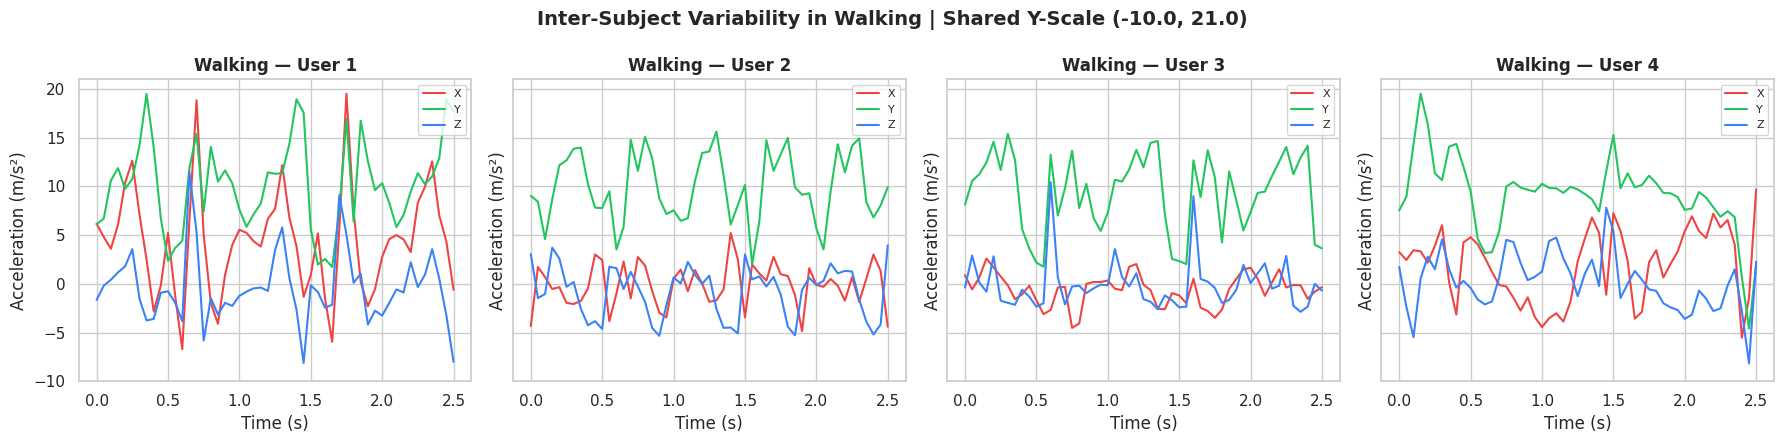

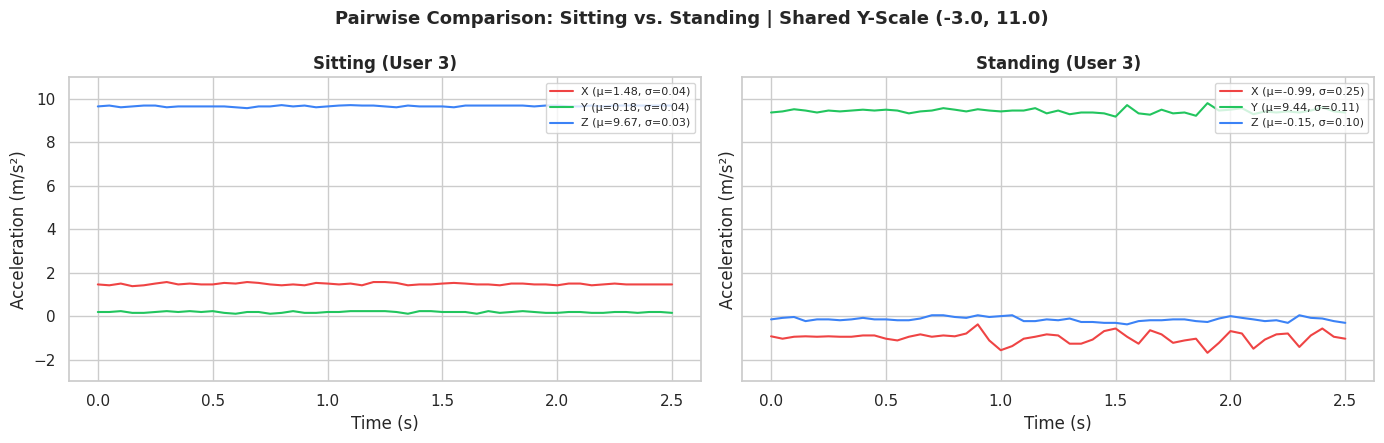

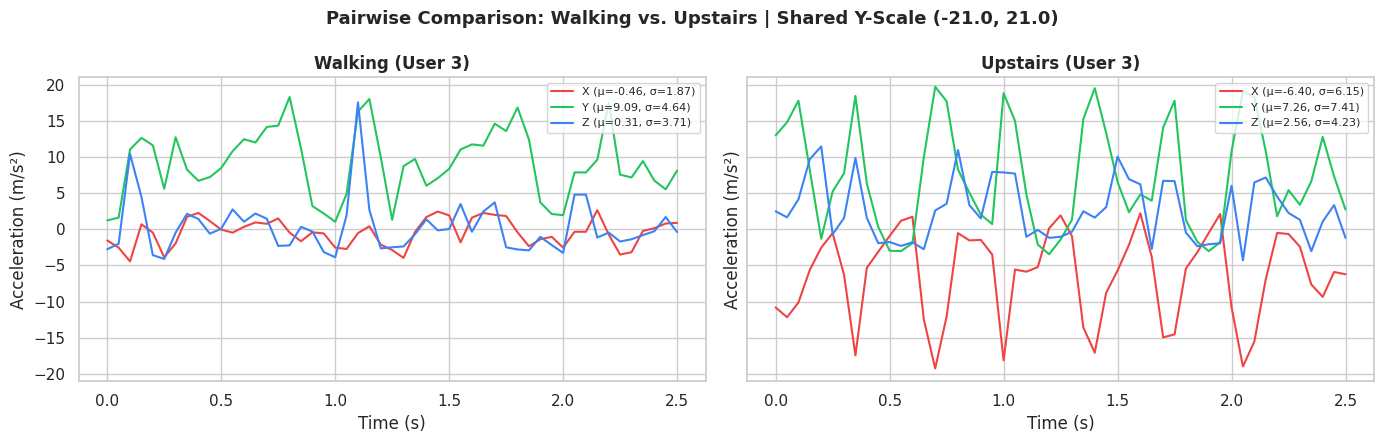

In [5]:
# 2-3: Inter-subject comparison for Walking across 4 participants
walk_users = user_act_matrix[user_act_matrix["Walking"] >= 500].index.tolist()[:4]
walk_windows = {u: get_clean_window(df, u, "Walking", WINDOW_SIZE, offset=200) for u in walk_users}

w_vals = np.concatenate([w[["x", "y", "z"]].values.ravel() for w in walk_windows.values()])
w_ylim = (float(np.floor(w_vals.min()) - 1), float(np.ceil(w_vals.max()) + 1))

fig, axes = plt.subplots(1, len(walk_users), figsize=(18, 4.5), sharex=True, sharey=True)
for ax, u in zip(axes, walk_users):
    w = walk_windows[u]
    ax.plot(TIME_AXIS, w["x"], label="X", color="#ef4444")
    ax.plot(TIME_AXIS, w["y"], label="Y", color="#22c55e")
    ax.plot(TIME_AXIS, w["z"], label="Z", color="#3b82f6")
    ax.set_title(f"Walking — User {u}", fontweight="bold")
    ax.set_ylim(w_ylim)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Acceleration (m/s²)")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle(f"Inter-Subject Variability in Walking | Shared Y-Scale {w_ylim}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 2-4: Pairwise comparisons (Sitting vs. Standing, Walking vs. Upstairs)
pairs = [("Sitting", "Standing"), ("Walking", "Upstairs")]

for act1, act2 in pairs:
    w1 = get_clean_window(df, common_user, act1, WINDOW_SIZE, offset=150)
    w2 = get_clean_window(df, common_user, act2, WINDOW_SIZE, offset=150)
    pair_vals = np.concatenate([w1[["x", "y", "z"]].values.ravel(), w2[["x", "y", "z"]].values.ravel()])
    pair_ylim = (float(np.floor(pair_vals.min()) - 1), float(np.ceil(pair_vals.max()) + 1))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True, sharey=True)
    for ax, act, w in zip(axes, [act1, act2], [w1, w2]):
        ax.plot(TIME_AXIS, w["x"], label=f"X (μ={w['x'].mean():.2f}, σ={w['x'].std():.2f})", color="#ef4444")
        ax.plot(TIME_AXIS, w["y"], label=f"Y (μ={w['y'].mean():.2f}, σ={w['y'].std():.2f})", color="#22c55e")
        ax.plot(TIME_AXIS, w["z"], label=f"Z (μ={w['z'].mean():.2f}, σ={w['z'].std():.2f})", color="#3b82f6")
        ax.set_title(f"{act} (User {common_user})", fontweight="bold")
        ax.set_ylim(pair_ylim)
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Acceleration (m/s²)")
        ax.legend(loc="upper right", fontsize=8)

    plt.suptitle(f"Pairwise Comparison: {act1} vs. {act2} | Shared Y-Scale {pair_ylim}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

### Analysis — Part 2 Questions (2-2, 2-3, 2-4, and 2-6)

#### 2-2. Comparing All 6 Activities
- **Highest temporal variability:** Dynamic activities—especially **Jogging** (largest peak-to-peak amplitude and highest cadence), followed by **Walking**, **Upstairs**, and **Downstairs**.
- **Walking vs. Jogging:** `Jogging` exhibits much sharper impact spikes, larger peak-to-peak amplitude, and a higher step frequency than `Walking`.
- **Separating Sitting vs. Standing:** Both are static activities with near-zero temporal variance, so oscillation amplitude cannot separate them. They differ mainly in their **axis means (gravity vector projection)** due to thigh/pocket angle (more horizontal when sitting, more vertical when standing). Because phone placement varies across users, this separation is not universally reliable.
- **Role of gravity in static states:** At rest, the accelerometer measures Earth's gravity ($\approx 9.81\,\text{m/s}^2$) as a constant DC offset distributed across $X, Y, Z$ depending on phone orientation. Since users place phones in pockets at different angles and orientations, no single axis can be assumed to represent gravity for every subject.
- **Is a single short window always sufficient?** No; a 2.55-second window may capture a brief pause, body turn, or activity transition, making definitive single-window classification unreliable in isolation.

#### 2-3. Inter-Subject Variability
- Waveforms and amplitudes for `Walking` differ noticeably across individuals (different stride frequencies, impact magnitudes, and even swapped dominant axes).
- **Contributing factors:** Height and stride length, body weight, natural walking pace, footwear, and—most critically—**phone placement and orientation** (left vs. right pocket, loose vs. tight clothing, upright vs. upside down).
- **Effect on generalization & splitting:** A model trained and tested on the same subjects memorizes user-specific biometrics and pocket orientations rather than general activity patterns. Splitting by `User ID` is required to measure real-world generalization to unseen users.

#### 2-4. Confusable Activity Pairs
- **Sitting vs. Standing:** Both appear as nearly flat lines with tiny standard deviations; they differ primarily in mean DC offsets across $X, Y, Z$. These visual cues are probabilistic evidence rather than strict rules (e.g., if a phone rests in a chest pocket, the orientation barely changes between sitting and standing).
- **Walking vs. Upstairs:** Both show quasi-periodic gait cycles. `Upstairs` often displays a slightly slower, less symmetric rhythm and shifted vertical/forward acceleration profiles, yet many individual windows look visually similar and are easily confused by simple models.

#### 2-6. Proposed Features (Preparation for PT2)
1. **Standard Deviation of Signal Vector Magnitude ($\sigma_{\|\mathbf{a}\|}$):** Captures overall motion intensity independently of phone orientation. Strongly separates static activities (`Sitting`/`Standing`) from dynamic ones, as well as `Jogging` from `Walking`. Varies across users with speed/energy, but remains invariant to phone rotation.
2. **Per-Axis Mean ($\mu_x, \mu_y, \mu_z$):** Captures the static gravitational DC offset and device tilt. Essential for distinguishing `Sitting` from `Standing`, though heavily sensitive to individual phone orientation.
3. **Peak-to-Peak Range / Signal Energy (RMS):** Measures maximum impact force and kinetic energy per window. Separates high-impact `Jogging` from moderate `Walking` and stair activities. Sensitive to user weight, footwear, and gait aggressiveness.
4. **Mean-Crossing Rate / Dominant Frequency:** Captures step cadence (repetition rate), helping distinguish fast `Jogging`, moderate `Walking`, and slower `Upstairs`/`Downstairs`. Varies across individuals due to height and natural stride length.

### 2-5. Interactive In-Notebook Dashboard (`Plotly + ipywidgets`)
Use the controls below to explore activities and compare participants without re-running code. The **Lock Shared Y-Axis** option is enabled by default to preserve scientific validity. A standalone Streamlit version (`dashboard.py`) is also provided alongside this notebook.

In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, clear_output

tab_mode = widgets.ToggleButtons(
    options=["Compare Activities (Same User)", "Compare Users (Same Activity)"],
    description="Mode:",
    style={"description_width": "initial"}
)
user_dropdown = widgets.Dropdown(
    options=sorted(df["user_id"].unique()),
    value=common_user,
    description="User ID:"
)
act_dropdown = widgets.Dropdown(
    options=activities_order,
    value="Walking",
    description="Activity:"
)
multi_acts = widgets.SelectMultiple(
    options=activities_order,
    value=("Walking", "Jogging", "Sitting", "Standing"),
    description="Activities:"
)
multi_users = widgets.SelectMultiple(
    options=sorted(df["user_id"].unique()),
    value=tuple(walk_users[:3]),
    description="Users:"
)
offset_slider = widgets.IntSlider(
    value=100, min=0, max=2000, step=26,
    description="Window Offset:",
    style={"description_width": "initial"}
)
lock_y = widgets.Checkbox(value=True, description="Lock Shared Y-Axis (Scientifically Accurate)")
out_plot = widgets.Output()

def update_dashboard(*args):
    with out_plot:
        clear_output(wait=True)
        if tab_mode.value == "Compare Activities (Same User)":
            selected = list(multi_acts.value)
            if not selected:
                print("Select at least one activity.")
                return
            u = user_dropdown.value
            windows, titles = [], []
            for act in selected:
                w = get_clean_window(df, u, act, WINDOW_SIZE, offset_slider.value)
                if w is not None:
                    windows.append((act, w))
                    titles.append(f"{act} (User {u})")
            if not windows:
                print(f"User {u} does not have enough data for the selected activities.")
                return
        else:
            selected = list(multi_users.value)
            if not selected:
                print("Select at least one participant.")
                return
            act = act_dropdown.value
            windows, titles = [], []
            for u in selected:
                w = get_clean_window(df, u, act, WINDOW_SIZE, offset_slider.value)
                if w is not None:
                    windows.append((f"User {u}", w))
                    titles.append(f"{act} — User {u}")
            if not windows:
                print(f"None of the selected users have enough data for {act}.")
                return

        n = len(windows)
        cols = min(2, n)
        rows = int(np.ceil(n / cols))
        fig = make_subplots(rows=rows, cols=cols, subplot_titles=titles, shared_yaxes=lock_y.value)

        all_y = np.concatenate([w[["x", "y", "z"]].values.ravel() for _, w in windows])
        yrange = [float(np.floor(all_y.min()) - 1), float(np.ceil(all_y.max()) + 1)]

        summary_rows = []
        for idx, (label, w) in enumerate(windows):
            r, c = divmod(idx, cols)
            r, c = r + 1, c + 1
            show_leg = (idx == 0)
            fig.add_trace(go.Scatter(x=TIME_AXIS, y=w["x"], name="X", line=dict(color="#ef4444"), showlegend=show_leg), row=r, col=c)
            fig.add_trace(go.Scatter(x=TIME_AXIS, y=w["y"], name="Y", line=dict(color="#22c55e"), showlegend=show_leg), row=r, col=c)
            fig.add_trace(go.Scatter(x=TIME_AXIS, y=w["z"], name="Z", line=dict(color="#3b82f6"), showlegend=show_leg), row=r, col=c)
            if lock_y.value:
                fig.update_yaxes(range=yrange, row=r, col=c)
            fig.update_xaxes(title_text="Time (s)", row=r, col=c)
            fig.update_yaxes(title_text="Acc (m/s²)", row=r, col=c)

            mag = np.sqrt(w["x"]**2 + w["y"]**2 + w["z"]**2)
            summary_rows.append({
                "Series": label,
                "X Mean": w["x"].mean(), "X Std": w["x"].std(),
                "Y Mean": w["y"].mean(), "Y Std": w["y"].std(),
                "Z Mean": w["z"].mean(), "Z Std": w["z"].std(),
                "Mag Std": mag.std(), "Mag Range": mag.max() - mag.min()
            })

        fig.update_layout(height=360 * rows, title_text="Interactive WISDM Signal Explorer", template="plotly_white")
        fig.show()
        display(pd.DataFrame(summary_rows).round(3))

for ctrl in [tab_mode, user_dropdown, act_dropdown, multi_acts, multi_users, offset_slider, lock_y]:
    ctrl.observe(update_dashboard, names="value")

controls_ui = widgets.VBox([
    tab_mode,
    widgets.HBox([user_dropdown, act_dropdown, lock_y]),
    widgets.HBox([multi_acts, multi_users]),
    offset_slider
])
display(controls_ui, out_plot)
update_dashboard()

Output()

---
## Part 3: Time-Series Windowing

We segment the raw stream into fixed-length windows of **51 samples (~2.55 s)** with a **step size of 26 samples** (25-sample overlap, ~49%).  
A new contiguous segment starts whenever `user_id` or `activity` changes, guaranteeing that **no window ever crosses a participant or activity boundary**.

In [7]:
WINDOW_SIZE = 51
STEP_SIZE = 26  # 25-sample overlap (~49%)

def create_windows(dataframe, window_size=51, step_size=26):
    """
    Segment raw sequences into fixed-length sliding windows.
    A new contiguous segment starts whenever user_id or activity changes,
    guaranteeing no window crosses a participant or activity boundary.
    """
    boundary_change = (
        (dataframe["user_id"] != dataframe["user_id"].shift(1)) |
        (dataframe["activity"] != dataframe["activity"].shift(1))
    )
    segment_ids = boundary_change.cumsum()

    X_list, y_list, user_list = [], [], []

    for _, seg in dataframe.groupby(segment_ids, sort=False):
        n_samples = len(seg)
        if n_samples < window_size:
            continue
        vals = seg[["x", "y", "z"]].values
        u_id = seg["user_id"].iloc[0]
        act = seg["activity"].iloc[0]

        for start in range(0, n_samples - window_size + 1, step_size):
            end = start + window_size
            X_list.append(vals[start:end])
            y_list.append(act)
            user_list.append(u_id)

    X = np.array(X_list, dtype=np.float32)  # Shape: (N_windows, 51, 3)
    y = np.array(y_list)
    users = np.array(user_list, dtype=np.int32)
    return X, y, users

X_win, y_win, users_win = create_windows(df, WINDOW_SIZE, STEP_SIZE)

print(f"Window array shape (X_win): {X_win.shape}  -> (N_windows, 51 samples, 3 axes)")
print(f"Total raw records         : {len(df):,}")
print(f"Total windows generated   : {len(X_win):,}")
print(f"Compression ratio         : {len(df) / len(X_win):.2f}x")

win_counts = pd.Series(y_win).value_counts().reindex(activities_order)
raw_counts = df["activity"].value_counts().reindex(activities_order)
comparison_df = pd.DataFrame({
    "Raw Samples": raw_counts,
    "Raw (%)": (raw_counts / len(df) * 100).round(2),
    "Windows (51/26)": win_counts,
    "Windows (%)": (win_counts / len(X_win) * 100).round(2)
})
display(comparison_df)

Window array shape (X_win): (41656, 51, 3)  -> (N_windows, 51 samples, 3 axes)
Total raw records         : 1,098,208
Total windows generated   : 41,656
Compression ratio         : 26.36x


,Raw Samples,Raw (%),Windows (51/26),Windows (%)
Walking,424399,38.64,16233,38.97
Jogging,342179,31.16,13083,31.41
Upstairs,122869,11.19,4549,10.92
Downstairs,100427,9.14,3693,8.87
Sitting,59939,5.46,2270,5.45
Standing,48395,4.41,1828,4.39


### Analysis — Part 3 Questions
- **Window and step size:** A sliding window extracts a contiguous 51-sample slice ($\approx 2.55\,\text{s}$ at 20 Hz) capturing 1–2 full gait cycles. A step size of 26 advances the window by 26 samples, creating a 25-sample ($\approx 49\%$) overlap between consecutive windows.
- **Why windows instead of single samples?** A single timestamp only records instantaneous acceleration and carries no information about rhythm, periodicity, or temporal dynamics required to recognize an activity.
- **Effect of increasing overlap:** Increases the number of training windows and prevents losing patterns that straddle non-overlapping window edges.
- **Are overlapping windows independent?** No; consecutive windows share nearly half of their exact samples and are strongly correlated.
- **Problem with mixed-activity windows:** Introduces label ambiguity (label noise)—assigning a single majority label forces the model to learn a corrupted hybrid pattern under one class.

---
## Part 4: Subject-Wise Data Splitting & Leakage Prevention

We partition the 36 participants into disjoint **Train (24 users)**, **Validation (6 users)**, and **Test (6 users)** subsets and verify programmatically that zero participants overlap across splits.

Subject-wise split verified: zero participants overlap across Train, Val, and Test.

Train: 24 users | 28,709 windows (68.9%)
Val  :  6 users | 6,868 windows (16.5%)
Test :  6 users | 6,079 windows (14.6%)


,Train Count,Train (%),Val Count,Val (%),Test Count,Test (%)
Walking,10935,38.09,2614,38.06,2684,44.15
Jogging,8624,30.04,2108,30.69,2351,38.67
Upstairs,3291,11.46,760,11.07,498,8.19
Downstairs,2780,9.68,634,9.23,279,4.59
Sitting,1735,6.04,415,6.04,120,1.97
Standing,1344,4.68,337,4.91,147,2.42


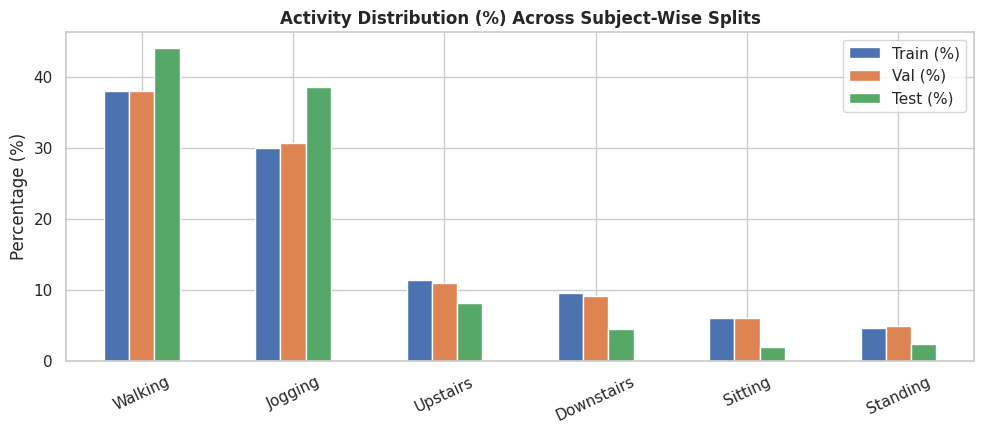

In [8]:
unique_users = np.sort(np.unique(users_win))
rng = np.random.default_rng(RANDOM_STATE)
shuffled_users = rng.permutation(unique_users)

n_total_users = len(shuffled_users)
n_train_u = int(round(0.67 * n_total_users))  # 24 users
n_val_u   = int(round(0.165 * n_total_users)) # 6 users

train_users = set(shuffled_users[:n_train_u])
val_users   = set(shuffled_users[n_train_u : n_train_u + n_val_u])
test_users  = set(shuffled_users[n_train_u + n_val_u :])

# Strict zero-overlap assertions
assert train_users.isdisjoint(val_users), "Leakage detected: shared users between Train and Val!"
assert train_users.isdisjoint(test_users), "Leakage detected: shared users between Train and Test!"
assert val_users.isdisjoint(test_users), "Leakage detected: shared users between Val and Test!"
assert len(train_users | val_users | test_users) == n_total_users
print("Subject-wise split verified: zero participants overlap across Train, Val, and Test.")

train_mask = np.isin(users_win, list(train_users))
val_mask   = np.isin(users_win, list(val_users))
test_mask  = np.isin(users_win, list(test_users))

X_train, y_train, u_train = X_win[train_mask], y_win[train_mask], users_win[train_mask]
X_val,   y_val,   u_val   = X_win[val_mask],   y_win[val_mask],   users_win[val_mask]
X_test,  y_test,  u_test  = X_win[test_mask],  y_win[test_mask],  users_win[test_mask]

print(f"\nTrain: {len(train_users):2d} users | {len(X_train):,} windows ({len(X_train)/len(X_win)*100:.1f}%)")
print(f"Val  : {len(val_users):2d} users | {len(X_val):,} windows ({len(X_val)/len(X_win)*100:.1f}%)")
print(f"Test : {len(test_users):2d} users | {len(X_test):,} windows ({len(X_test)/len(X_win)*100:.1f}%)")

split_dist = pd.DataFrame({
    "Train Count": pd.Series(y_train).value_counts().reindex(activities_order, fill_value=0),
    "Train (%)": (pd.Series(y_train).value_counts(normalize=True).reindex(activities_order, fill_value=0) * 100).round(2),
    "Val Count": pd.Series(y_val).value_counts().reindex(activities_order, fill_value=0),
    "Val (%)": (pd.Series(y_val).value_counts(normalize=True).reindex(activities_order, fill_value=0) * 100).round(2),
    "Test Count": pd.Series(y_test).value_counts().reindex(activities_order, fill_value=0),
    "Test (%)": (pd.Series(y_test).value_counts(normalize=True).reindex(activities_order, fill_value=0) * 100).round(2),
})
display(split_dist)

split_dist[["Train (%)", "Val (%)", "Test (%)"]].plot(kind="bar", figsize=(10, 4.5))
plt.title("Activity Distribution (%) Across Subject-Wise Splits", fontweight="bold")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Analysis — Part 4 Questions
- **Why random window splitting causes Data Leakage:** First, adjacent overlapping windows share ~49% identical data points; putting one in Train and its neighbor in Test leaks test data directly into training. Second, user-specific gait and phone orientation appear in both splits, allowing the model to recognize the *person* rather than the *activity*.
- **Random split vs. Subject-wise split:** Random window splitting produces artificially inflated (optimistic) metrics, whereas subject-wise splitting yields a realistic estimate of true generalization error.
- **More realistic estimate:** **Subject-wise Split**, because real-world deployments must generalize to completely unseen users.

---
## Part 5: Baseline Models and Evaluation

We flatten each `(51, 3)` window into a 153-element vector and evaluate three baselines:
1. **Majority Class Classifier** (`DummyClassifier(strategy="most_frequent")`)
2. **Logistic Regression** (with `StandardScaler` fitted strictly inside a `Pipeline` on the Training set, tuned on Validation)
3. **Decision Tree** (tuned on Validation)

Final metrics—Accuracy, per-class Precision/Recall/F1, **Macro-F1**, and Confusion Matrices—are reported on the untouched held-out **Test Set**.

[Val] LogisticRegression (C=0.01) -> Acc: 0.5460 | Macro-F1: 0.3681
[Val] LogisticRegression (C=0.1 ) -> Acc: 0.5457 | Macro-F1: 0.3699
[Val] LogisticRegression (C=1.0 ) -> Acc: 0.5454 | Macro-F1: 0.3697
[Val] LogisticRegression (C=10.0) -> Acc: 0.5459 | Macro-F1: 0.3700
-----------------------------------------------------------------
[Val] DecisionTree (max_depth=5   ) -> Acc: 0.5762 | Macro-F1: 0.3296
[Val] DecisionTree (max_depth=10  ) -> Acc: 0.6615 | Macro-F1: 0.5250
[Val] DecisionTree (max_depth=15  ) -> Acc: 0.6755 | Macro-F1: 0.6189
[Val] DecisionTree (max_depth=20  ) -> Acc: 0.6522 | Macro-F1: 0.6371
[Val] DecisionTree (max_depth=None) -> Acc: 0.6261 | Macro-F1: 0.6348

================ Majority Class (Test Set Report) ================
              precision    recall  f1-score   support

     Walking       0.44      1.00      0.61      2684
     Jogging       0.00      0.00      0.00      2351
    Upstairs       0.00      0.00      0.00       498
  Downstairs       0.00    

,Model,Train Accuracy,Train Macro-F1,Test Accuracy,Test Macro-F1
0,Majority Class,0.3809,0.0919,0.4415,0.1021
1,Logistic Regression (C=10.0),0.5792,0.3750,0.5705,0.3642
2,Decision Tree (depth=20),0.9275,0.9100,0.6718,0.5685


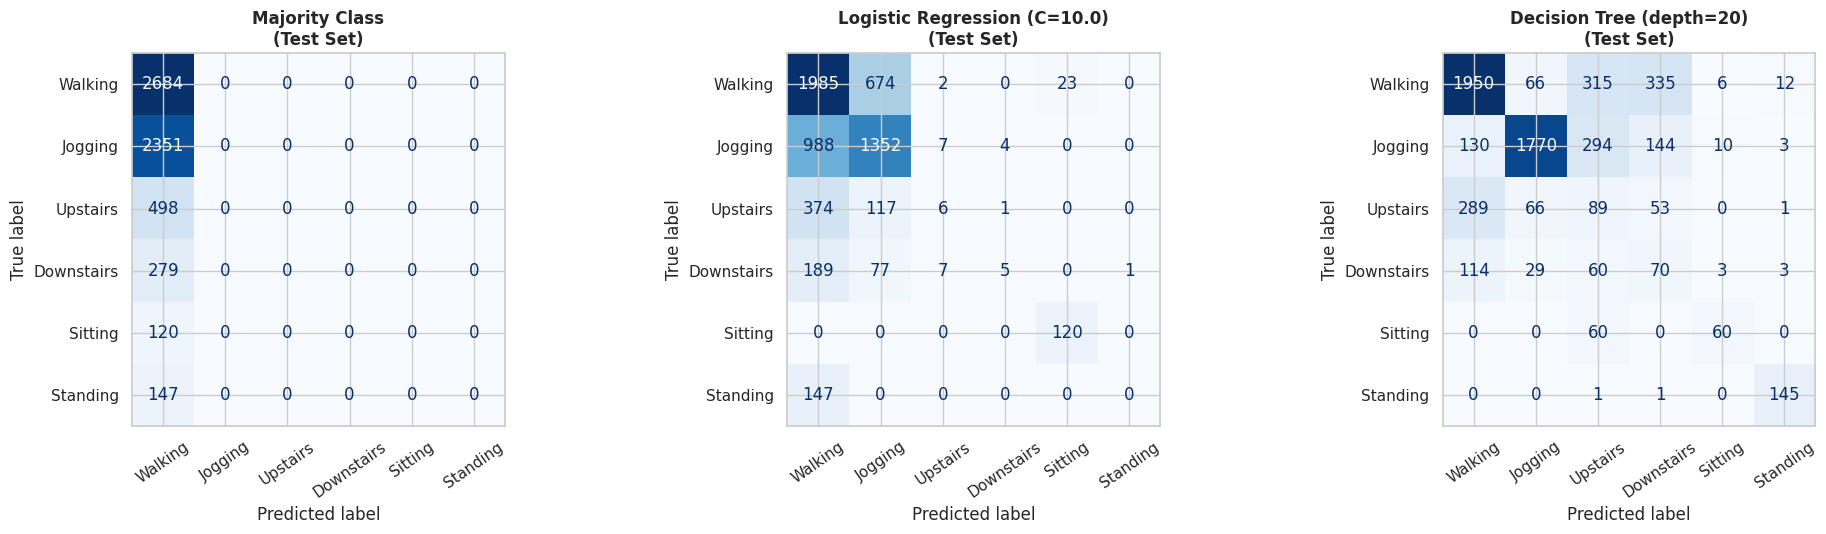

In [9]:
# Flatten (N, 51, 3) windows into (N, 153) vectors
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat   = X_val.reshape(len(X_val), -1)
X_test_flat  = X_test.reshape(len(X_test), -1)

# 1. Majority Class Baseline
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train_flat, y_train)

# 2. Logistic Regression (tuned strictly on Validation Set)
best_lr_model, best_lr_f1, best_c = None, -1.0, None
for C_val in [0.01, 0.1, 1.0, 10.0]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=C_val, max_iter=1000, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train_flat, y_train)
    val_pred = pipe.predict(X_val_flat)
    val_f1 = f1_score(y_val, val_pred, average="macro")
    print(f"[Val] LogisticRegression (C={C_val:<4}) -> Acc: {accuracy_score(y_val, val_pred):.4f} | Macro-F1: {val_f1:.4f}")
    if val_f1 > best_lr_f1:
        best_lr_f1, best_lr_model, best_c = val_f1, pipe, C_val

print("-" * 65)

# 3. Decision Tree (tuned strictly on Validation Set)
best_dt_model, best_dt_f1, best_depth = None, -1.0, None
for depth in [5, 10, 15, 20, None]:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    dt.fit(X_train_flat, y_train)
    val_pred = dt.predict(X_val_flat)
    val_f1 = f1_score(y_val, val_pred, average="macro")
    print(f"[Val] DecisionTree (max_depth={str(depth):<4}) -> Acc: {accuracy_score(y_val, val_pred):.4f} | Macro-F1: {val_f1:.4f}")
    if val_f1 > best_dt_f1:
        best_dt_f1, best_dt_model, best_depth = val_f1, dt, depth

# 4. Final Evaluation on Held-Out Test Set
models_to_eval = {
    "Majority Class": dummy_clf,
    f"Logistic Regression (C={best_c})": best_lr_model,
    f"Decision Tree (depth={best_depth})": best_dt_model,
}

results_summary = []
for name, model in models_to_eval.items():
    tr_pred = model.predict(X_train_flat)
    te_pred = model.predict(X_test_flat)
    results_summary.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, tr_pred),
        "Train Macro-F1": f1_score(y_train, tr_pred, average="macro"),
        "Test Accuracy": accuracy_score(y_test, te_pred),
        "Test Macro-F1": f1_score(y_test, te_pred, average="macro"),
    })
    print(f"\n================ {name} (Test Set Report) ================")
    print(classification_report(y_test, te_pred, labels=activities_order, zero_division=0))

print("\n=== Final Model Comparison Summary ===")
display(pd.DataFrame(results_summary).round(4))

# 5. Confusion Matrices on Test Set
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (name, model) in zip(axes, models_to_eval.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_flat), labels=activities_order)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=activities_order)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)
    ax.set_title(f"{name}\n(Test Set)", fontweight="bold")

plt.tight_layout()
plt.show()

---
## Section 5 (Assignment Report): Complete Answers to All 8 Analytical Questions

1. **Why is Human Activity Recognition a sequential classification problem?**  
   Human activities unfold dynamically over time, so consecutive accelerometer readings are temporally dependent. The identity of an activity lies not in isolated measurements, but in temporal structure—periodicity, oscillation amplitude, and step-impact patterns across time.

2. **What is the difference between raw accelerometer data and extracted time windows?**  
   Raw data form a continuous time series of instantaneous 3D vectors $(x_t, y_t, z_t)$ that cannot be directly fed into standard tabular classifiers. Windowing converts this stream into fixed-length observations (each a $51 \times 3$ matrix or 153-element vector) paired with a single activity label.

3. **What are the benefits and limitations of overlapping windows?**  
   *Benefits:* Increases sample count and ensures transitional or periodic peaks are not cut in half at window boundaries.  
   *Limitations:* Introduces strong statistical correlation between adjacent windows, increases compute cost, and causes severe data leakage if windows are split randomly.

4. **Why must windows from the same participant never be split across Train and Test?**  
   Because of both direct sample overlap (~49%) and shared user-specific motion signatures/device placement, splitting a user across Train and Test lets the model memorize user identity instead of learning generalizable activity representations.

5. **Is Accuracy alone sufficient? Why is Macro-F1 critical here?**  
   No. Because WISDM is heavily imbalanced (~38.6% `Walking` vs. ~4.4% `Standing`), even a trivial Majority Class classifier achieves ~39–44% accuracy while getting 0% recall on the other 5 classes. **Macro-F1** averages the F1-score equally across all 6 classes regardless of class size, immediately exposing poor performance on minority classes.

6. **What explains a large drop in Test performance compared to Train performance?**  
   (a) **Overfitting** to raw flattened signals (especially in deep decision trees, which easily hit ~100% training accuracy);  
   (b) **Inter-subject distribution shift**, as test users have different gait patterns, speeds, and pocket orientations than training users; and  
   (c) **Phase-shift sensitivity**—flattening raw time steps assumes peaks occur at the exact same sample index across windows, which rarely holds.

7. **Can good performance on WISDM be expected to hold identically for new real-world users?**  
   No. WISDM was collected under controlled conditions (36 participants, phone mostly in a front trouser pocket, 6 predefined activities, limited device models). Real-world usage involves varied phone locations (hand, backpack, shirt pocket), mixed/unlabeled activities, transitions, and heterogeneous sensor noise/sampling rates.

8. **Based on visual inspection, which activities are easiest and hardest for a simple baseline classifier?**  
   *Easiest:* **Jogging** (distinctively high amplitude and energy) and **Walking** (high sample count and clean periodic rhythm), plus broad separation between static and dynamic groups.  
   *Hardest:* **Upstairs** and **Downstairs** (fewer samples and strong waveform similarity to `Walking` and to each other) and **Sitting vs. Standing** on unseen users (both are flat signals separated only by gravity orientation, which shifts with phone placement). Furthermore, flattened raw vectors lack shift invariance, motivating the statistical and frequency-domain feature engineering explored in PT2.

![Screenshot 2026-11-20 164944.png](<screenshots\164944.png>)

![Screenshot 2026-11-20 165033.png](<screenshots\165033.png>)

![Screenshot 2026-11-20 165114.png](<screenshots\165114.png>)